# Joel Greenblatt's Magic Formula

The study below replicates Joel Greenblatt's well-known investment strategy, which consists of selecting stocks of companies with good fundamentals at attractive prices. The strategy is based on two criteria: return on capital (ROC) and earnings yield (EBIT/EV). The data for this study was collected from the Comdinheiro platform; the collection code is in the `brazil-equity-factors` repository.

In [1]:
# Library imports

import pandas as pd
import numpy as np
import statsmodels.api as sm
import quantstats as qs
from scipy import stats
from tqdm import tqdm

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.dates as mdates

from datetime import date, timedelta
from  bizdays import Calendar, set_option

cal = Calendar.load('ANBIMA')
cal_b3 = Calendar.load('B3')
set_option('mode', 'pandas')

### Settings from earlier versions

These are files imported and processed from the Comdinheiro API that were worked on in earlier versions of this notebook. Dates are converted to the datetime.date format.

In [2]:
# Imports data already collected to make the analysis easier

path = 'data/'

companies = pd.read_csv(path + 'index_composition.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
prices_df = pd.read_csv(path + 'prices.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
market_value = pd.read_csv(path + 'relative_market_value.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
earnings_yield = pd.read_csv(path + 'earnings_yield_mf.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
roc = pd.read_csv(path + 'roc_mf.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
debt_ebit = pd.read_csv(path + 'debt_ebit_mf.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
benchmarks = pd.read_csv(path + 'benchmarks.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
nefin = pd.read_csv(path + 'nefin_factors.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')
volume = pd.read_csv(path + 'volume.csv.gz', index_col = 'Date', date_format='%Y-%m-%d')

# Index rebalancing dates
rebalance_dates = sorted(companies.index.unique())

# Backtest dates
ini_date = date(2008,12,31)
end_date = date(2024,12,31)

In [3]:
# Volatility and momentum calculation
volatility = prices_df.pct_change(fill_method = None).rolling(252).std().mul(np.sqrt(252))
momentum = (prices_df.shift(21) / prices_df.shift(252)).sub(1)

In [4]:
# Data treatment to remove repeated tickers from the stock universe
# The main ticker is selected based on trading volume

ticker_codes = [tick[0:4] for tick in sorted(companies['Ticker'].unique())]
repeated_tickers = [tick for tick in ticker_codes if ticker_codes.count(tick) > 1]
repeated_tickers = list(dict.fromkeys(repeated_tickers))

vol_median = volume.ffill(limit=1).rolling(42).median()

for tick in repeated_tickers:
    rep = volume.columns[volume.columns.str.contains(tick)]
    ticker_filter = vol_median[rep].apply(lambda r: np.where(r == r.max(), r, np.nan), axis = 1)
    vol_median[rep] = pd.DataFrame(ticker_filter.tolist(), columns = rep, index = vol_median.index)

# Building the portfolios and backtesting the strategy

In the section below we build a table with the investable companies for each date since 2009, and we also build the portfolios with the best and worst companies according to the Magic Formula methodology.

The portfolio has a total number of companies and is built up over one year: for example, a portfolio with 24 companies is built up over the year with quarterly purchases of 6 companies until it reaches the total. From that point on, the 6 oldest companies are swapped for the 6 newest on the swap date.

## Investable companies

For this step we need to check which companies may or may not be part of the portfolio on the date it is built; the criterion is in the companies table, which holds the composition of the MLCX and SMLL indices, collected in January, May and September of each year. 
<br>A company investable on January 5, 2009 can be placed in the portfolio until May 4, 2009, when a new composition was collected; if it appears again, it continues in the investable sample.

- The 'investable' dataframe shows which companies can be considered on every day of the sample: 1 means it is part of the sample and 0 that it is excluded from that period.

In [5]:
# Creates a matrix with the investable companies on each rebalancing date, showing the new index composition
investable = companies.loc[(companies['Index'].isin(['MLCX', 'SMLL'])) & (~companies['Sector'].isin(['Financeiro', 'Financeiro e Outros', 'Utilidade Pública']))].pivot_table(index = 'Date', columns = 'Ticker', values = 'Weight')

# Multiplies by 0 and adds 1 to turn all values into 1, indicating that the company is investable
investable = investable.mul(0).add(1)

# Reindexes the table so that all backtest dates are present
investable = investable.reindex(market_value.index, method='ffill')
investable.loc[:date(2009,1,2)] = investable.loc[date(2009,1,5):date(2009,1,5)].values

# Creates a dataframe showing whether the stock had a price on the day, avoiding companies that left the market
has_price = prices_df.apply(lambda col: np.where((col.isna()) | (col <= 0), np.nan, 1)).loc[investable.index]

# Creates a dataframe to filter companies with low liquidity, avoiding companies whose prices are a problem to trade
volume_filter = vol_median.apply(lambda col: np.where(col > 1000, 1, np.nan))

# Filters the dataframe dates to the range between ini_date and end_date
prices_df = prices_df.loc[ini_date:end_date]
market_value = market_value.loc[ini_date:end_date]
benchmarks = benchmarks.loc[ini_date:end_date]
nefin = nefin.loc[ini_date:end_date]

investable = investable.loc[ini_date:end_date]
has_price = has_price.loc[ini_date:end_date]
volume_filter = volume_filter.loc[ini_date:end_date]

earnings_yield = earnings_yield.loc[ini_date:end_date]
roc = roc.loc[ini_date:end_date]
debt_ebit = debt_ebit.loc[ini_date:end_date]
volatility = volatility.loc[ini_date:end_date]
momentum = momentum.loc[ini_date:end_date]

## Final Ranking

The final rank is the sum of a company's positions with respect to ROC and EY, for example:
<br>PETR4 has the 2nd best ROC and the 11th best EY, so its value in the final ranking is 2 + 11, that is, 13.
<br>
<br>To build the rank for all dates in the period, we filter the ROC and EY tables by the investable table and then rank the indicator tables for all dates. The final rank table is the sum of the two other tables; empty values are already handled by the mathematical operations between the tables, so only companies that have both indicators on the date take part in the rank.

In [6]:
# Multiplies the indicators dataframe by investable and has_price to filter all dates at once
# Values in roc and earnings_yield multiplied by NaN become NaN, leaving only the values of companies that are investable on the date and have a price
roc = roc * investable * has_price * volume_filter
earnings_yield = earnings_yield * investable * has_price * volume_filter
debt_ebit = debt_ebit * investable * has_price * volume_filter
volatility = volatility * investable * has_price * volume_filter
momentum = momentum * investable * has_price * volume_filter

# Ranks the stocks for all dates, without changing the order of the values
# The rank() function only replaces the value with its position in the rank
roc_rank = roc.rank(ascending = False, axis = 1)
ey_rank = earnings_yield.rank(ascending = False, axis = 1)
debt_rank = debt_ebit.rank(ascending = True, axis = 1)
vol_rank = volatility.rank(ascending = True, axis = 1)
mom_rank = momentum.rank(ascending = False, axis = 1)

# Adds the two dataframes to get the final rank according to the formula
# The addition also works as a filter for null values, n + NaN = NaN
final_rank = roc_rank + ey_rank
mf_debt_rank = roc_rank + ey_rank + debt_rank
mf_mom_rank = roc_rank + ey_rank + mom_rank
mf_mom_vol_rank = roc_rank + ey_rank + mom_rank + vol_rank
mf_vol_rank = roc_rank + ey_rank + vol_rank
mf_mixed_rank = roc_rank + ey_rank + debt_rank + mom_rank + vol_rank

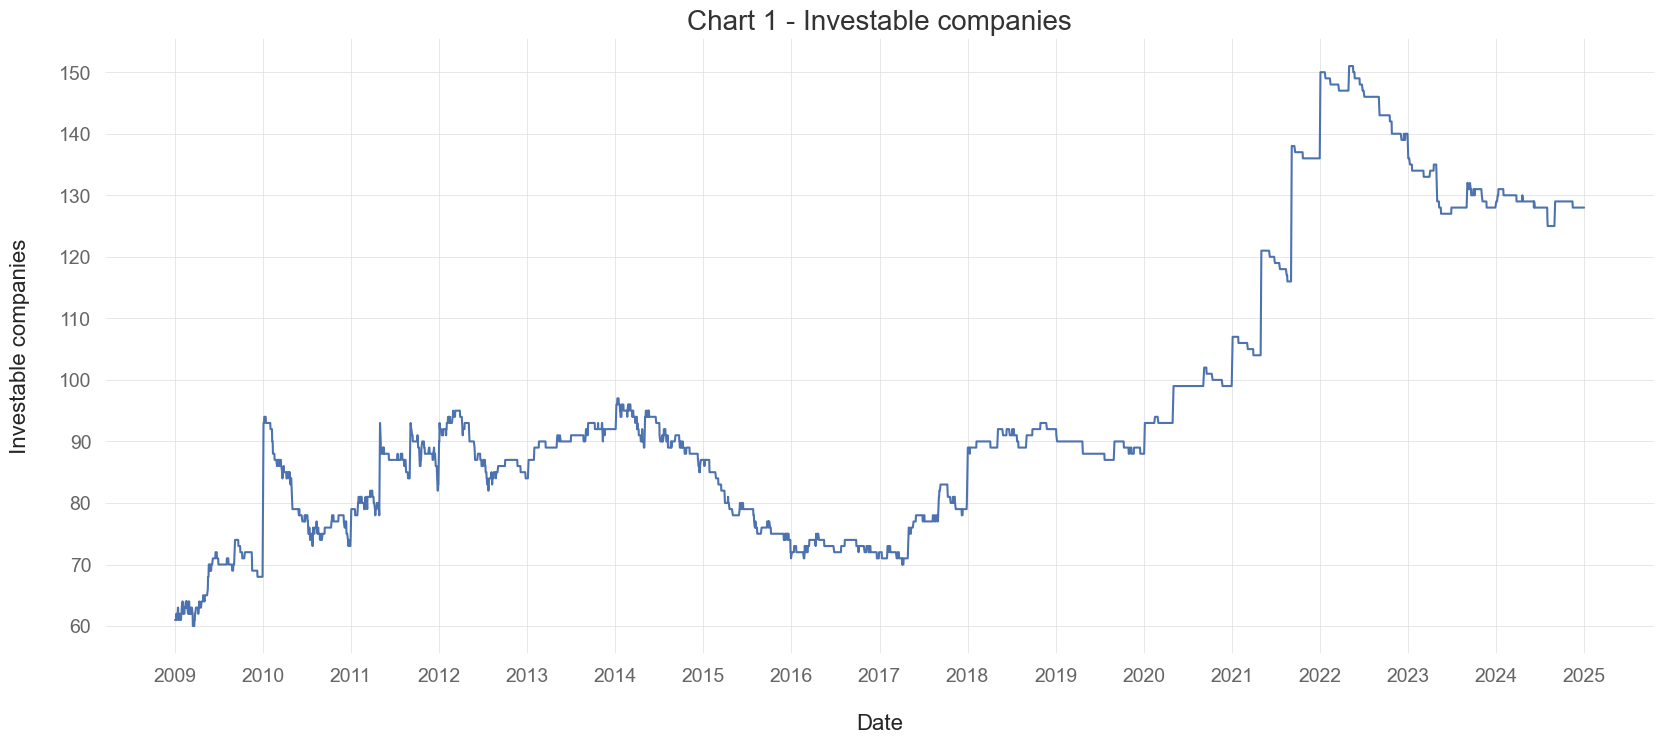

In [7]:
plt.figure(figsize=(20, 8))
plt.title('Chart 1 - Investable companies', fontsize = 20)
plt.plot(investable.mul(has_price * volume_filter).sum(axis = 1).loc[date(2009,1,1):date(2025,1,1)])
plt.yticks(np.arange(60, 160, 10), fontsize=14)
plt.ylabel('Investable companies\n', fontsize=16)
plt.xticks(fontsize=14)
plt.xlabel('\nDate', fontsize=16)

plt.gca().xaxis.set_major_locator(mdates.YearLocator(1))  # Major ticks every 1 year
plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y'))  # Formats the dates to show only the year

plt.grid(True, which='both')
plt.show()

# Functions for building the portfolios and backtests

## Building the Magic Formula portfolio

The portfolio, as mentioned above, may have a larger number of companies and be built over the year; the settings can be edited to build a portfolio of different sizes, number of purchases in the year and how many stocks to buy at a time. Two settings were added to the function to run different backtests:
- bottom: if you want the worst companies instead of the best, set this parameter to True;
- new_stocks_only: returns only the stocks bought on the date instead of the full portfolio; this makes a difference when calculating the backtest and is explained in the corresponding step.

In [8]:
from magic_formula.portfolio import magic_formula_portfolio

## Functions for the Magic Formula backtest

The backtest function has two methods:
- All stocks are rebalanced on the purchase dates, with equal weights or according to the companies' market value;
- The new stocks form a "new portfolio" and these portfolios have a 1-year lock-up, that is, 'n' portfolios run simultaneously to make up the final return; the only rebalancing divides the weight equally among the independent portfolios, no longer among the stocks.

<br>The results in this notebook use only the first method, with equal weights.

In [9]:
from magic_formula.weights import compute_weights

In [10]:
from magic_formula.backtest import adjust_position

In [11]:
from magic_formula.backtest import backtest

In [12]:
from magic_formula.backtest import backtest_total

## Functions for the quintile and Long-Short backtests

Now we look at the magic formula from another perspective: we divide the companies in the rank into quintiles, the first quintile being the 20% best ranked and the fifth quintile the 20% worst. The goal is to analyze the persistence of performance in each group; if the author's theory is correct, the first quintile will perform better than the second, and so on. The backtest in this case weights the stocks equally.

In [13]:
from magic_formula.weights import compute_directional_weights, compute_longshort_weights

In [14]:
from magic_formula.selection import get_quintiles, get_longshort

In [15]:
from magic_formula.backtest import backtest_quintiles, backtest_longshort

# Backtests and performance analysis of the strategies

## Magic Formula backtest

The backtest_total function returns the Long portfolio based on the information passed. We run some tests below varying the ranking used and checking their results; in addition, we can change the portfolio through the variables below, obtaining completely different portfolios:

- rebalance_dates: number of rebalancing dates
- portfolio_size: total number of assets
- buy_size: number of stocks bought at a time until the total is reached; it also indicates how much turnover the portfolio can have.

In [16]:
# Creates a list with all rebalancing dates
rebalance_dates = [date(year, month, 1) for year in range(2009, 2025) for month in [1,4,7,10]]
# rebalance_dates = [date(year, month, 1) for year in range(2009, 2025) for month in range(1,13)]
# rebalance_dates = [date(year, 1, 1) for year in range(2009, 2025)]

# Checks whether the date is a business day, if not, returns the next business day
rebalance_dates = [cal.following(ref_date) for ref_date in rebalance_dates if ref_date < date.today()]

portfolio_size = 24
buy_size = 6

# Return of a portfolio with 24 companies, buying 6 stocks on each date in rebalance_dates
ret_mf = backtest_total(rebalance_dates, final_rank, prices_df, market_value, portfolio_size, buy_size, weight_type = 'equal')
ret_roc = backtest_total(rebalance_dates, roc_rank, prices_df, market_value, portfolio_size, buy_size, weight_type = 'equal')
ret_ey = backtest_total(rebalance_dates, ey_rank, prices_df, market_value, portfolio_size, buy_size, weight_type = 'equal')
ret_debt = backtest_total(rebalance_dates, debt_rank, prices_df, market_value, portfolio_size, buy_size, weight_type = 'equal')
ret_mom = backtest_total(rebalance_dates, mom_rank, prices_df, market_value, portfolio_size, buy_size, weight_type = 'equal')
ret_vol = backtest_total(rebalance_dates, vol_rank, prices_df, market_value, portfolio_size, buy_size, weight_type = 'equal')
ret_mf_debt = backtest_total(rebalance_dates, mf_debt_rank, prices_df, market_value, portfolio_size, buy_size, weight_type = 'equal')
ret_mf_mom = backtest_total(rebalance_dates, mf_mom_rank, prices_df, market_value, portfolio_size, buy_size, weight_type = 'equal')
ret_mf_vol = backtest_total(rebalance_dates, mf_vol_rank, prices_df, market_value, portfolio_size, buy_size, weight_type = 'equal')
ret_mf_mom_vol = backtest_total(rebalance_dates, mf_mom_vol_rank, prices_df, market_value, portfolio_size, buy_size, weight_type = 'equal')
ret_mf_mixed = backtest_total(rebalance_dates, mf_mixed_rank, prices_df, market_value, portfolio_size, buy_size, weight_type = 'equal')

# total_returns = pd.concat([equal_totalrebal, equal_portlrebal, vm_totalrebal, vm_portrebal, vol_totalrebal, var_totalrebal, sharpe_totalrebal], axis = 1)
total_returns = pd.concat([ret_mf, ret_roc, ret_ey, ret_debt, ret_mom, ret_vol, ret_mf_debt, ret_mf_mom, ret_mf_vol, ret_mf_mom_vol, ret_mf_mixed], axis = 1).loc[cal_b3.seq(ini_date, end_date)]
total_returns.columns = ['MF', 'Return on Capital', 'Earnings Yield', 'Debt to Ebit', 'Momentum', 'Volatility', 'MF Debt', 'MF Mom', 'MF Vol', 'MF Mom Vol', 'MF Mixed']

### Analysis of the results

In the section below we present the results of the Long strategies, varying the ranking used, calculating some risk-adjusted return statistics, comparing with some benchmarks used in the fund industry, and decomposing the returns based on the Fama-French risk factors: Market Beta, Size, Value, Momentum.

In [17]:
# Calculates the fixed income return
selic = (benchmarks + 1).prod()['SELIC'] ** (1 / (len(total_returns) / 252)) - 1
cdi = (benchmarks + 1).prod()['CDI'] ** (1 / (len(total_returns) / 252)) - 1

# Calculates the portfolio return, volatility and sharpe, all annualized
vol = total_returns.dropna().std().mul(np.sqrt(252))
ret = total_returns.dropna().mean().mul(252)
sharpe = total_returns.apply(lambda col: col - benchmarks['CDI']).dropna().mean().mul(252) / vol
dd = qs.stats.max_drawdown(total_returns)
ttest = stats.ttest_1samp(total_returns.dropna(), popmean = 0)[0]

# Creates a dataframe with the results
results = pd.DataFrame({'Return': ret, 'Volatility': vol, 'Sharpe': sharpe, 'Max Drawdown': dd, 'T-test': ttest})

In [18]:
total_returns.dropna().resample('YE').apply(lambda r: (r + 1).prod() - 1).to_csv('results/annual_returns_strategies.csv')

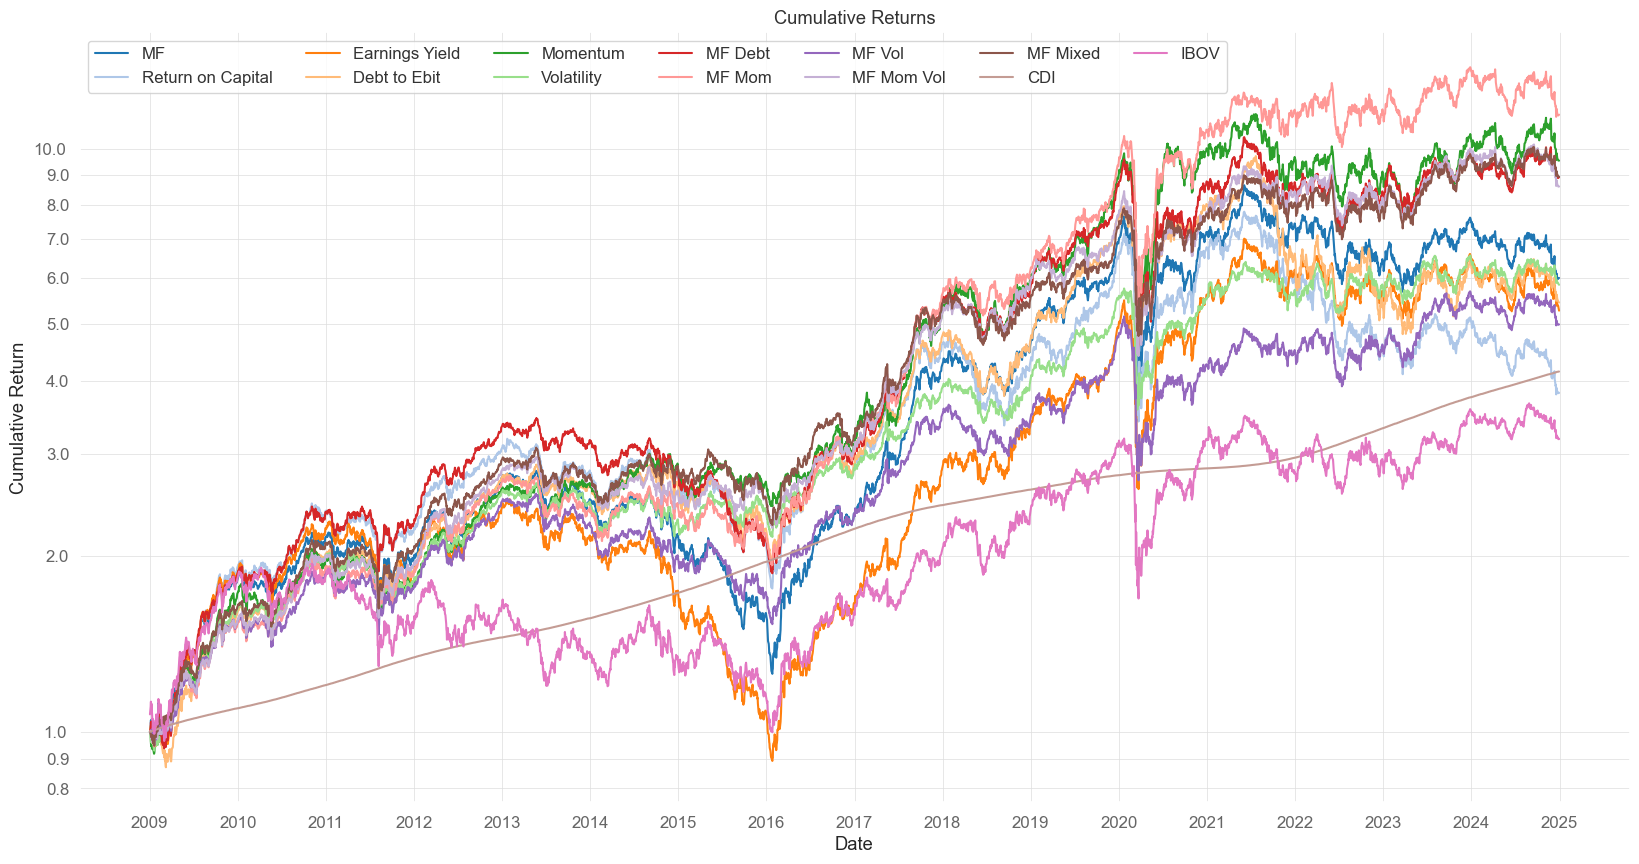

In [19]:
# Creates a dataframe with the portfolio and benchmark returns to compare them graphically
returns = total_returns.merge(benchmarks[['CDI', 'IBOV']], how = 'left', left_index = True, right_index = True).dropna()
returns_cumpounded = (returns + 1).cumprod()

# Creates a chart with the cumulative returns of the portfolio and the benchmarks
fig, ax = plt.subplots(figsize = (20, 10))
ax.set_prop_cycle(color = plt.cm.tab20.colors)
for col in returns_cumpounded.columns:
    ax.plot(returns_cumpounded.index, returns_cumpounded[col], label = col)
ax.set_title('Cumulative Returns')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative Return')
ax.set_yscale('log')
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))
ax.yaxis.set_minor_formatter(ticker.FormatStrFormatter('%.1f'))
ax.xaxis.set_major_locator(mdates.YearLocator(1))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.legend(ncol = 7, loc = 'upper left')
ax.grid(True, which = 'both')
plt.show()

In [20]:
# Merges the returns with the risk factors
factors = total_returns.merge(nefin, how = 'left', left_index = True, right_index = True).dropna()
factors.index = pd.to_datetime(factors.index)

# Creates a dataframe to store the risk factor parameters
factors_params, factors_errors, factors_pvalues = pd.DataFrame(), pd.DataFrame(), pd.DataFrame()
for col in total_returns.columns:
    # Calculates the monthly returns
    factors = factors.resample('ME').agg(lambda x: (x + 1).prod() - 1)
    # Calculates the excess return and assigns the dependent variable
    Y = (factors[col]) - factors['Risk_Free']
    # Assigns the independent variables
    X = factors[['Rm_minus_Rf', 'SMB', 'HML', 'WML']]
    # Adds the constant (alpha) to the model
    X = sm.add_constant(X) 

    # Creates the regression model
    model = sm.OLS(Y, X).fit()
    # Stores the parameters in the dataframe
    factors_params[col] = np.concat(([Y.mean()], model.params.values, [model.rsquared_adj]))
    factors_errors[col] = model.bse
    factors_pvalues[col] = np.concat(([stats.ttest_1samp(Y, popmean = 0)[1]], model.pvalues.values))

# Renames the dataframe index
factors_params.index = ['Excess return', 'Alpha', 'MKT', 'SMB', 'HML', 'WML', 'Adjusted R²']
factors_errors.index = ['Alpha_std', 'MKT_std', 'SMB_std', 'HML_std', 'WML_std']
factors_pvalues.index = ['Excess return_pvalue', 'Alpha_pvalue', 'MKT_pvalue', 'SMB_pvalue', 'HML_pvalue', 'WML_pvalue']

pd.concat([results, factors_params.T, factors_errors.T, factors_pvalues.T], axis = 1).T.to_csv('results/statistics_strategies.csv')

## Quintile backtest

In this section we assess the performance of each quintile over the period, seeking to check the quality of the portfolio built and whether the idea of the magic formula holds along the ranking. To do so we compare the annual return, volatility and Sharpe of each portfolio.
<br>The portfolios are recalculated on the first day of each month based on the dates in rebalance_dates.

In [21]:
# Creates a list with all rebalancing dates
rebalance_dates = [date(year, month, 1) for year in range(2009, 2025) for month in range(1,13)]

# Checks whether the date is a business day, if not, returns the next business day
rebalance_dates = [cal.following(ref_date) for ref_date in rebalance_dates if ref_date < date.today()]

In [22]:
signals = {'MF':final_rank, 'Return on Capital':roc_rank, 'Earnings Yield':ey_rank, 
          'Debt to Ebit':debt_rank, 'Momentum':mom_rank, 'Volatility':vol_rank, 
          'MF Debt':mf_debt_rank, 'MF Mom':mf_mom_rank, 'MF Vol':mf_vol_rank, 
          'MF Mom Vol':mf_mom_vol_rank, 'MF Mixed':mf_mixed_rank}

# Creates a dictionary with the 5 quintiles and their companies
quintiles = {f'{k}_{(n+2)/2:.0f}Q': get_quintiles(n/10, (n+2)/10, v) for k,v in signals.items() for n in range(0,10,2)}

# Calculates the daily return for all quintiles
quintiles_returns = {k: backtest_quintiles(prices_df, v, rebalance_dates, market_value).loc[cal_b3.seq(ini_date, end_date)] for k,v in zip(quintiles.keys(), quintiles.values())}

# Calculates the return, volatility and sharpe for all quintiles
quintiles_returns_annual = {k: v.mean() * 252 for k,v in zip(quintiles.keys(), quintiles_returns.values())}
quintiles_vol_annual = {k: v.std() * np.sqrt(252) for k,v in zip(quintiles.keys(), quintiles_returns.values())}
quintiles_sharpe = {k: (v - cdi) / quintiles_vol_annual[k] for k,v in zip(quintiles.keys(), quintiles_returns_annual.values())}
quintiles_maxdd = {k: qs.stats.max_drawdown(v) for k,v in zip(quintiles.keys(), quintiles_returns.values())}
quintiles_ttest = {k: stats.ttest_1samp(v.dropna(), popmean = 0)[0] for k,v in zip(quintiles.keys(), quintiles_returns.values())}

# Creates a dataframe with the return, volatility and sharpe of all quintiles
quintiles_info = pd.DataFrame([quintiles_returns_annual, quintiles_vol_annual, quintiles_sharpe, quintiles_maxdd, quintiles_ttest], index = ['Return', 'Volatility', 'Sharpe', 'Max Drawdown', 'T-test'])

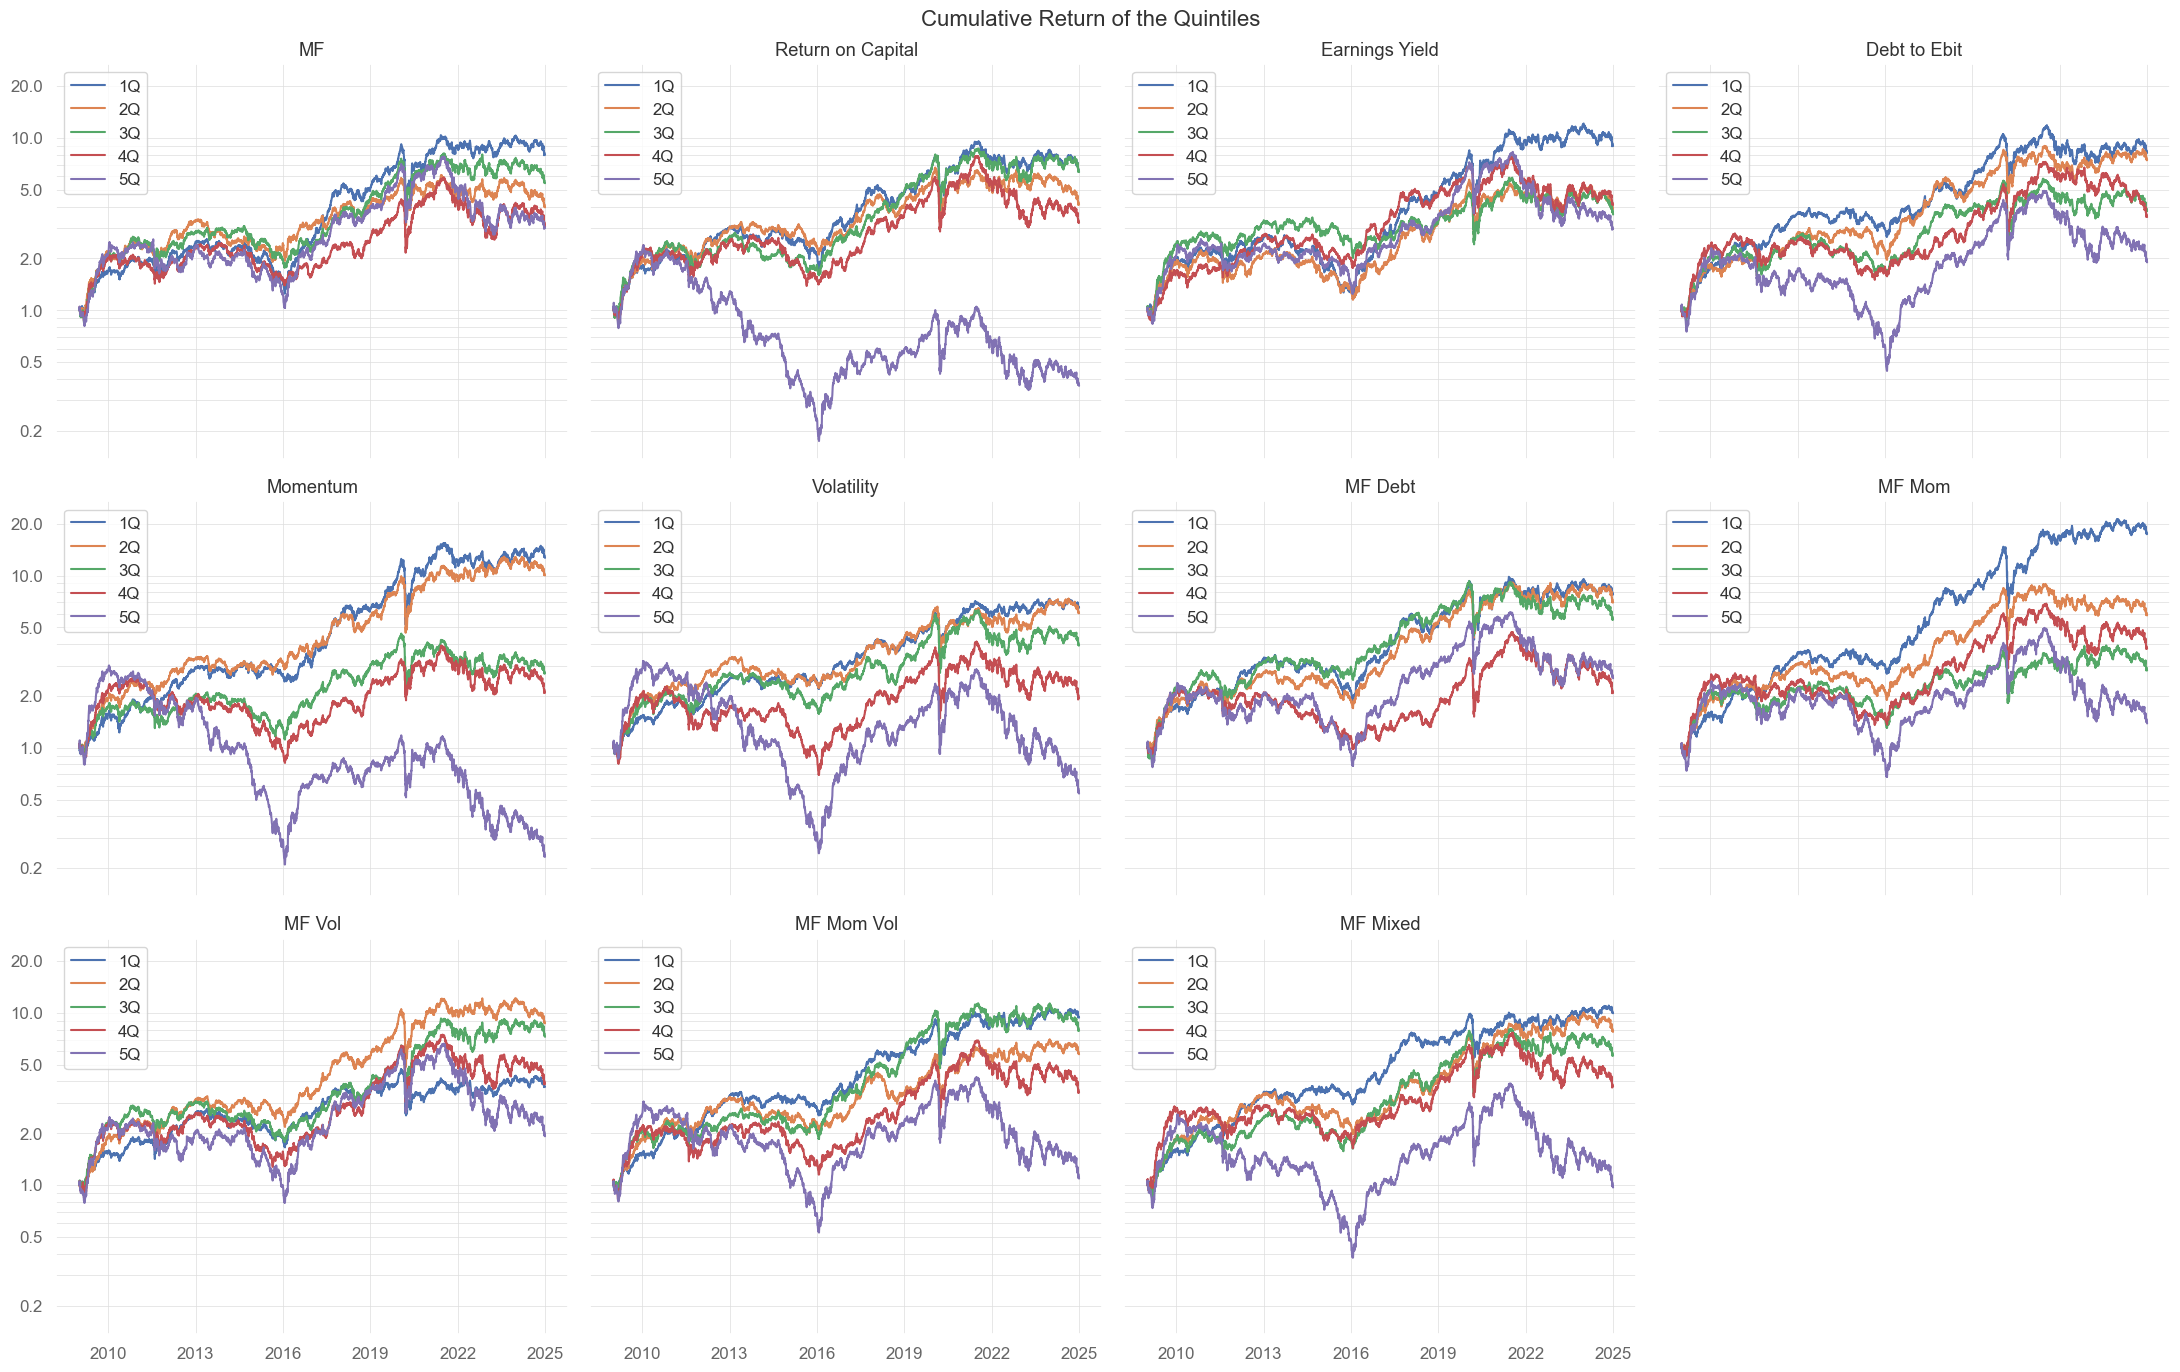

In [23]:
# Creates a dataframe with the quintile returns to compare them graphically
returns = pd.DataFrame(quintiles_returns).dropna()
# returns = returns.merge(benchmarks, left_index = True, right_index = True, how = 'left').dropna()
cumpounded_returns = returns.add(1).cumprod()

# Creates a chart with the cumulative return of all quintiles, one panel per strategy
fig, axes = plt.subplots(3, 4, figsize = (22, 14), sharex = True, sharey = True)
for ax, strategy in zip(axes.flat, signals.keys()):
    for col in cumpounded_returns.columns[cumpounded_returns.columns.str.startswith(strategy + '_')]:
        ax.plot(cumpounded_returns.index, cumpounded_returns[col], label = col.split('_')[-1])
    ax.set_title(strategy)
    ax.set_yscale('log')
    ax.set_yticks([0.2, 0.5, 1, 2, 5, 10, 20])
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))
    ax.yaxis.set_minor_formatter(ticker.NullFormatter())
    ax.xaxis.set_major_locator(mdates.YearLocator(3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.legend()
    ax.grid(True, which = 'both')
axes.flat[-1].set_visible(False)
fig.suptitle('Cumulative Return of the Quintiles', fontsize = 16)
plt.tight_layout()
plt.show()

In [24]:
returns.dropna().resample('YE').apply(lambda r: (r + 1).prod() - 1).to_csv('results/annual_returns_quintiles.csv')

In [25]:
# Merges with the risk factors
factors = returns.merge(nefin, how = 'left', left_index = True, right_index = True).merge(benchmarks[['IBOV', 'IBRX']], how = 'left', left_index = True, right_index = True).dropna()
factors = factors.loc[:end_date]
factors.index = pd.to_datetime(factors.index)

# Creates a dataframe to store the risk factor parameters
factors_params, factors_errors, factors_pvalues = pd.DataFrame(), pd.DataFrame(), pd.DataFrame()
for col in returns.columns.tolist() + ['IBOV', 'IBRX']:
    # Calculates the monthly returns
    factors = factors.resample('ME').agg(lambda x: (x + 1).prod() - 1)
    # Calculates the excess return and assigns the dependent variable
    Y = (factors[col]) - factors['Risk_Free']
    # Assigns the independent variables
    X = factors[['Rm_minus_Rf', 'SMB', 'HML', 'WML']]
    # Adds the constant (alpha) to the model
    X = sm.add_constant(X) 

    # Creates the regression model
    model = sm.OLS(Y, X).fit()
    # Stores the parameters in the dataframe
    factors_params[col] = np.concat(([Y.mean()], model.params.values, [model.rsquared_adj]))
    factors_errors[col] = model.bse
    factors_pvalues[col] = np.concat(([stats.ttest_1samp(Y, popmean = 0)[1]], model.pvalues.values))

# Renames the dataframe index
factors_params.index = ['Excess return', 'Alpha', 'MKT', 'SMB', 'HML', 'WML', 'Adjusted R²']
factors_errors.index = ['Alpha_std', 'MKT_std', 'SMB_std', 'HML_std', 'WML_std']
factors_pvalues.index = ['Excess return_pvalue', 'Alpha_pvalue', 'MKT_pvalue', 'SMB_pvalue', 'HML_pvalue', 'WML_pvalue']

pd.concat([quintiles_info, factors_params, factors_errors, factors_pvalues], axis = 0).to_csv('results/statistics_quintiles.csv')

## Long-Short backtest

Next we measure the premium generated by the strategy, this premium being the difference between the returns of the best and the worst. The portfolios built for this analysis have a long leg in the x% best and a short leg in the x% worst; we compare the results in the same way as we did with the quintiles.

In [26]:
# Defines the percentiles for the Long-Short portfolio
percentiles = [0.1, 0.2, 0.25, 0.30, 0.4, 0.5]
# Creates a dictionary with the Long-Short portfolios for each percentile
portfolios = {f'{k}_{n:.0%}': get_longshort(n, v) for k,v in signals.items() for n in percentiles}

# Calculates the Long-Short portfolio return for all percentiles
longshort_returns = {k: backtest_longshort(prices_df, v[1], v[0], rebalance_dates, market_value).loc[cal_b3.seq(ini_date, end_date)] for k,v in zip(portfolios.keys(), portfolios.values())}

# Calculates the return, volatility and sharpe for all Long-Short portfolios
# longshort_returns = {k: v + benchmarks['CDI'] for k,v in zip(longshort_returns.keys(), longshort_returns.values())}
longshorts_returns_annual = {k: v.mean() * 252 for k,v in zip(longshort_returns.keys(), longshort_returns.values())}
longshorts_vol_annual = {k: v.std() * np.sqrt(252) for k,v in zip(longshort_returns.keys(), longshort_returns.values())}
longshorts_sharpe = {k: (v) / longshorts_vol_annual[k] for k,v in zip(longshort_returns.keys(), longshorts_returns_annual.values())}
longshorts_maxdd = {k: qs.stats.max_drawdown(v) for k,v in zip(longshort_returns.keys(), longshort_returns.values())}
longshorts_ttest = {k: stats.ttest_1samp(v.dropna(), popmean = 0)[0] for k,v in zip(longshort_returns.keys(), longshort_returns.values())}

# Creates a dataframe with the return, volatility and sharpe of all Long-Short portfolios
longshorts_info = pd.DataFrame([longshorts_returns_annual, longshorts_vol_annual, longshorts_sharpe, longshorts_maxdd, longshorts_ttest], index = ['Return', 'Volatility', 'Sharpe', 'Max Drawdown', 'T-test'])

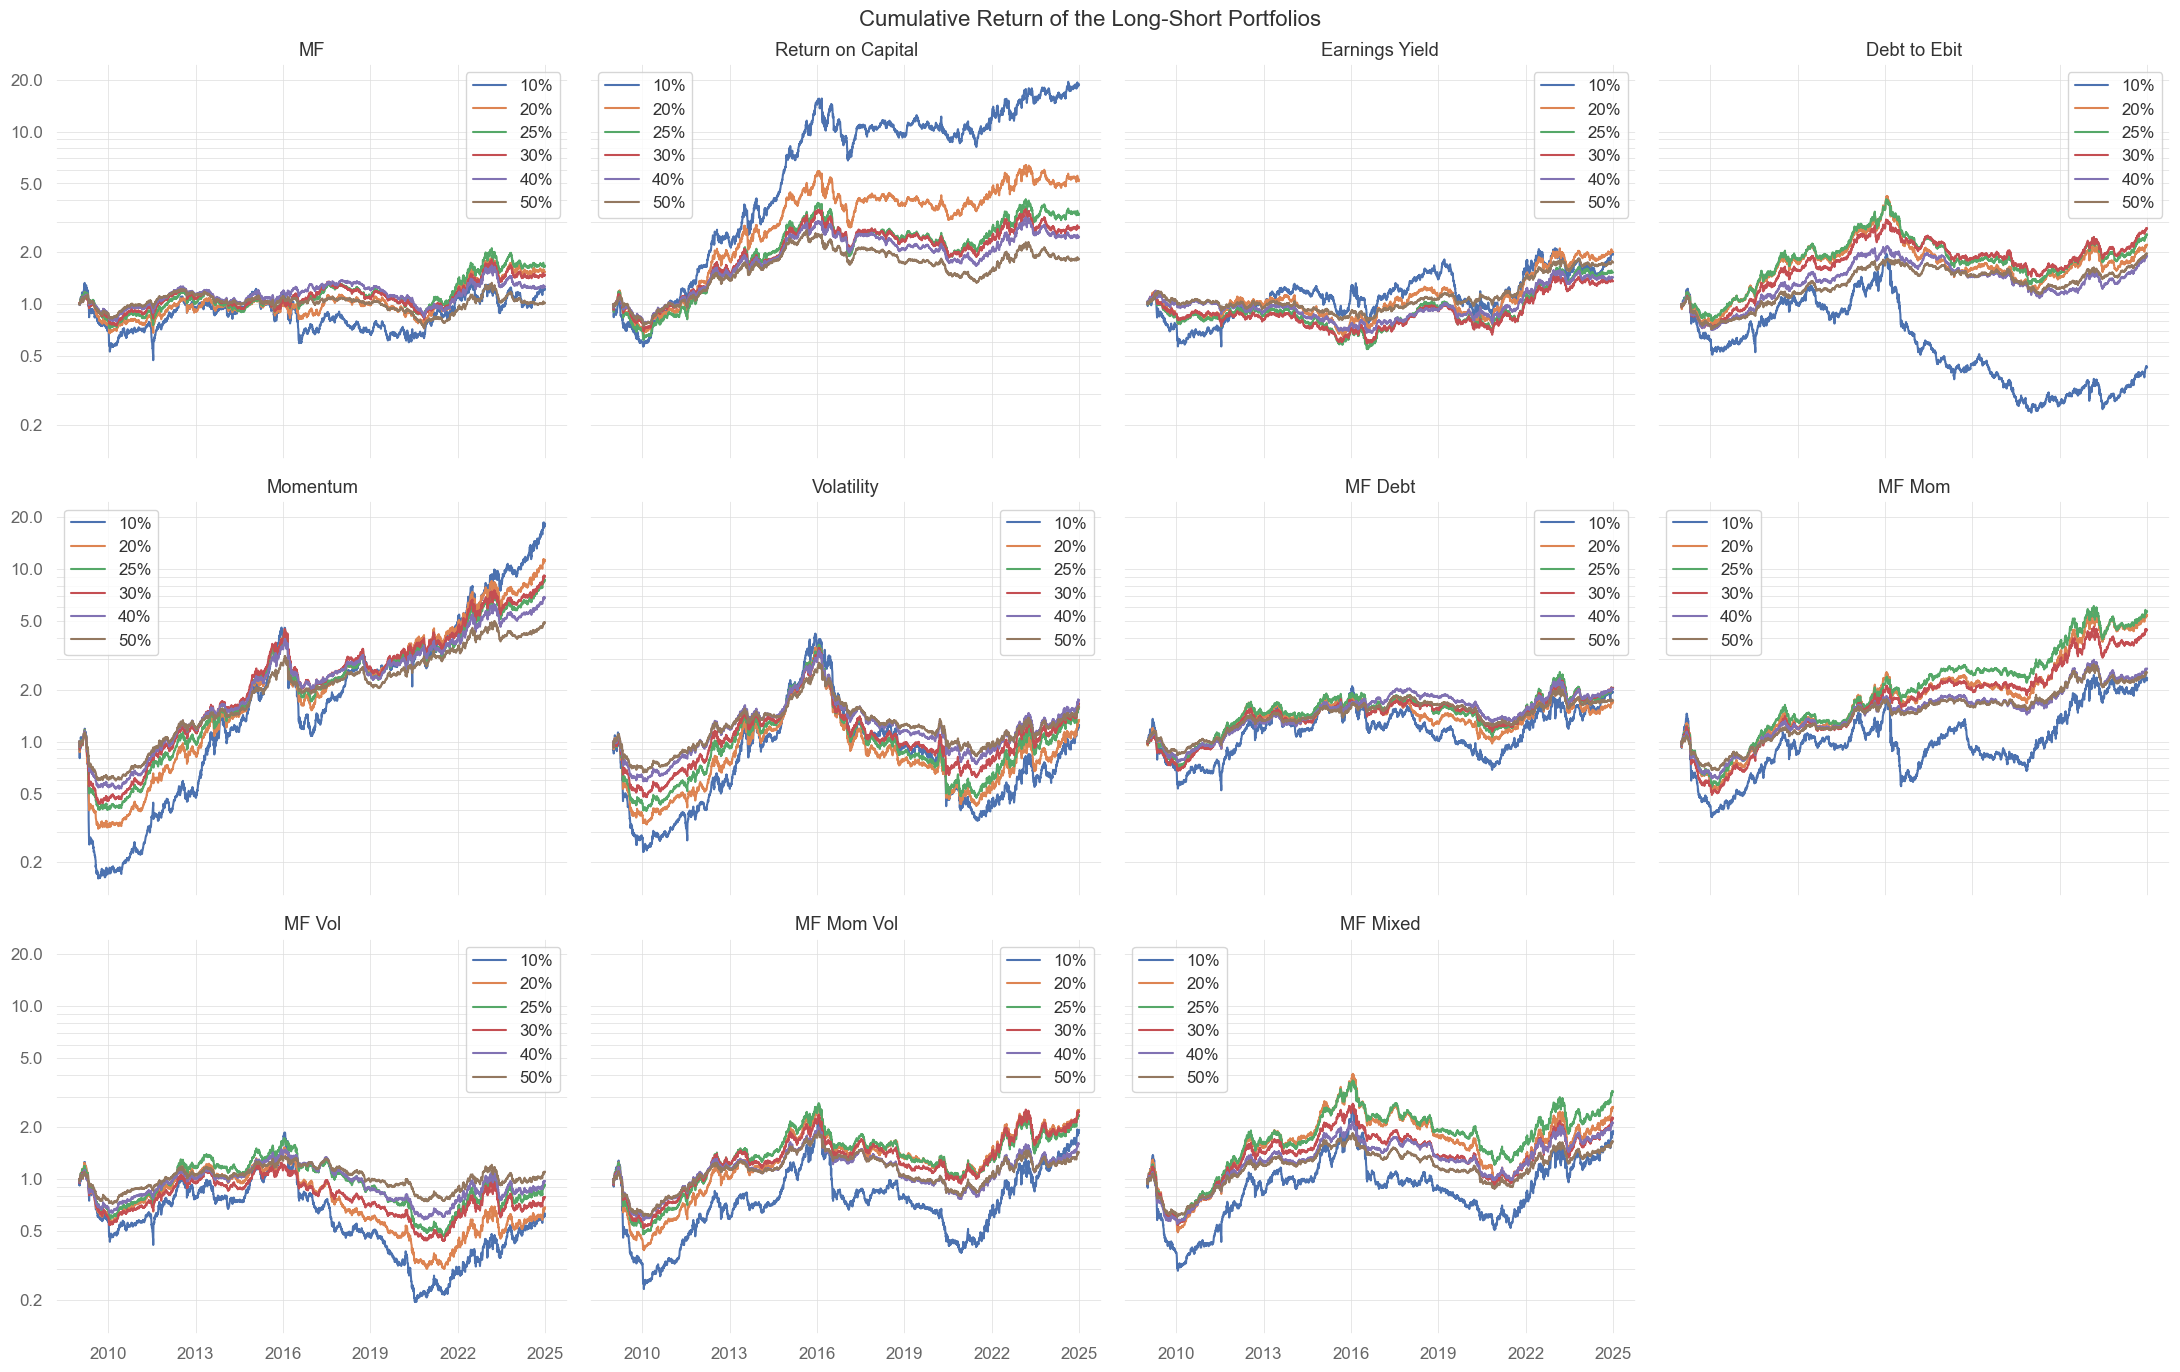

In [27]:
# Creates a dataframe with the Long-Short portfolio returns to compare them graphically
returns = pd.DataFrame(longshort_returns).dropna(how = 'all')
cumpounded_returns = returns.add(1).cumprod()

# Creates a chart with the cumulative return of all Long-Short portfolios, one panel per strategy
fig, axes = plt.subplots(3, 4, figsize = (22, 14), sharex = True, sharey = True)
for ax, strategy in zip(axes.flat, signals.keys()):
    for col in cumpounded_returns.columns[cumpounded_returns.columns.str.startswith(strategy + '_')]:
        ax.plot(cumpounded_returns.index, cumpounded_returns[col], label = col.split('_')[-1])
    ax.set_title(strategy)
    ax.set_yscale('log')
    ax.set_yticks([0.2, 0.5, 1, 2, 5, 10, 20])
    ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.1f'))
    ax.yaxis.set_minor_formatter(ticker.NullFormatter())
    ax.xaxis.set_major_locator(mdates.YearLocator(3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
    ax.legend()
    ax.grid(True, which = 'both')
axes.flat[-1].set_visible(False)
fig.suptitle('Cumulative Return of the Long-Short Portfolios', fontsize = 16)
plt.tight_layout()
plt.show()

In [28]:
returns.dropna().resample('YE').apply(lambda r: (r + 1).prod() - 1).to_csv('results/annual_returns_longshort.csv')

In [29]:
# Merges the returns with the risk factors
factors = returns.merge(nefin, how = 'left', left_index = True, right_index = True).dropna()
factors.index = pd.to_datetime(factors.index)

# Creates a dataframe to store the risk factor parameters
factors_params, factors_errors, factors_pvalues = pd.DataFrame(), pd.DataFrame(), pd.DataFrame()
for col in returns.columns:
    # Calculates the monthly returns
    factors = factors.resample('ME').agg(lambda x: (x + 1).prod() - 1)
    # Calculates the excess return and assigns the dependent variable
    Y = (factors[col])
    # Assigns the independent variables
    X = factors[['Rm_minus_Rf', 'SMB', 'HML', 'WML']]
    # Adds the constant (alpha) to the model
    X = sm.add_constant(X) 

    # Creates the regression model
    model = sm.OLS(Y, X).fit()
    # Stores the parameters in the dataframe
    factors_params[col] = np.concat(([Y.mean()], model.params.values, [model.rsquared_adj]))
    factors_errors[col] = model.bse
    factors_pvalues[col] = np.concat(([stats.ttest_1samp(Y, popmean = 0)[1]], model.pvalues.values))

# Renames the dataframe index
factors_params.index = ['Excess return', 'Alpha', 'MKT', 'SMB', 'HML', 'WML', 'Adjusted R²']
factors_errors.index = ['Alpha_std', 'MKT_std', 'SMB_std', 'HML_std', 'WML_std']
factors_pvalues.index = ['Excess return_pvalue', 'Alpha_pvalue', 'MKT_pvalue', 'SMB_pvalue', 'HML_pvalue', 'WML_pvalue']

pd.concat([longshorts_info, factors_params, factors_errors, factors_pvalues], axis = 0).to_csv('results/statistics_longshort.csv')

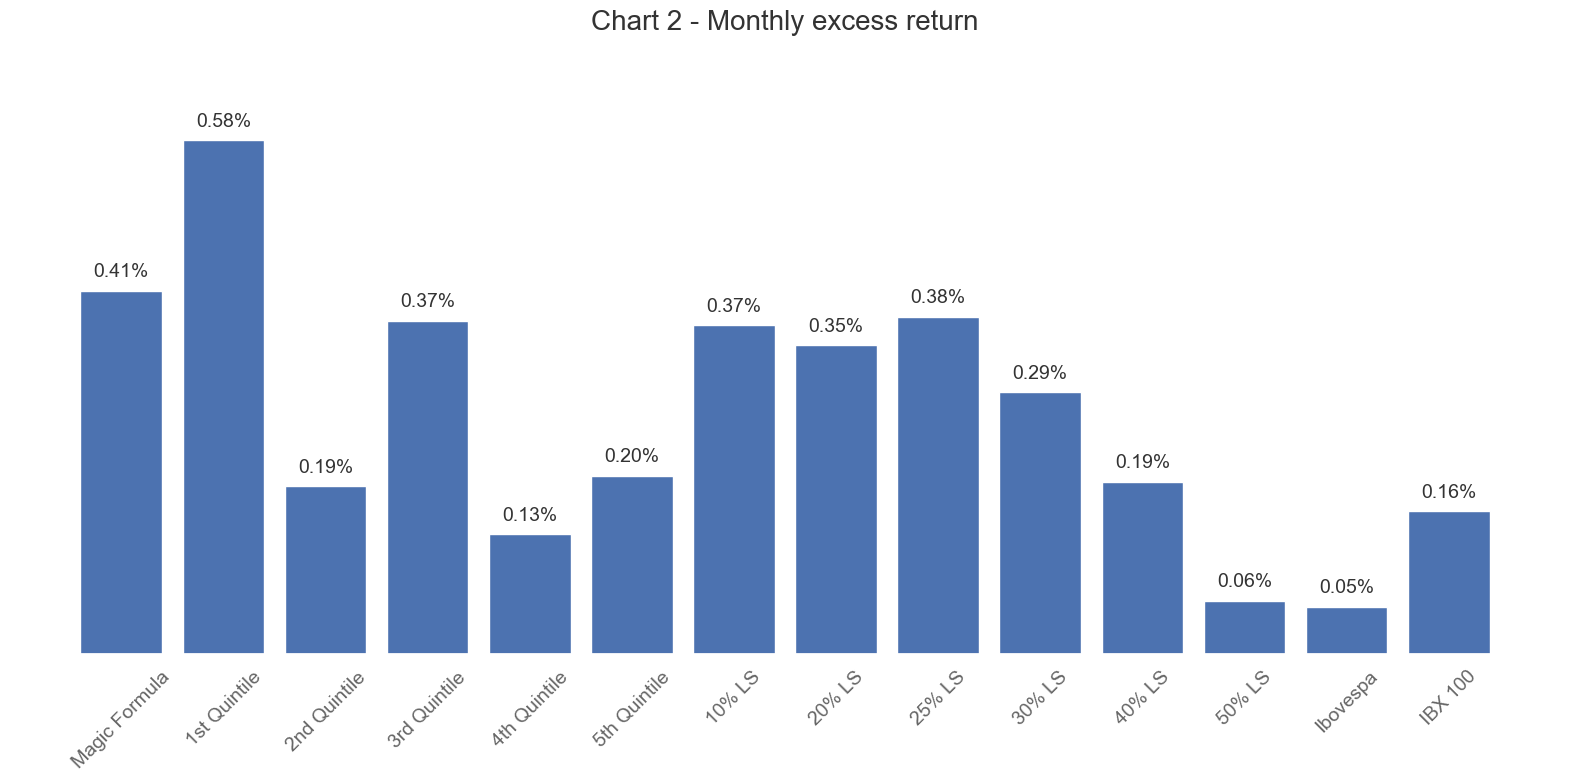

In [30]:
# Reads the excess returns from the tables saved above, so the chart follows the backtest
excess_strategies = pd.read_csv('results/statistics_strategies.csv', index_col = 0).loc['Excess return']
excess_quintiles = pd.read_csv('results/statistics_quintiles.csv', index_col = 0).loc['Excess return']
excess_longshorts = pd.read_csv('results/statistics_longshort.csv', index_col = 0).loc['Excess return']

excess_returns = {"Magic Formula": excess_strategies['MF'], "1st Quintile": excess_quintiles['MF_1Q'], "2nd Quintile": excess_quintiles['MF_2Q'], "3rd Quintile": excess_quintiles['MF_3Q'], "4th Quintile": excess_quintiles['MF_4Q'], "5th Quintile": excess_quintiles['MF_5Q'],
                  '10% LS': excess_longshorts['MF_10%'], '20% LS': excess_longshorts['MF_20%'], '25% LS': excess_longshorts['MF_25%'], '30% LS': excess_longshorts['MF_30%'], '40% LS': excess_longshorts['MF_40%'], '50% LS': excess_longshorts['MF_50%'], "Ibovespa": excess_quintiles['IBOV'], "IBX 100": excess_quintiles['IBRX']}

excess_returns_series = pd.Series(excess_returns)

plt.figure(figsize=(20, 8))
plt.title('Chart 2 - Monthly excess return', fontsize = 20)
plt.bar(excess_returns_series.index, excess_returns_series.values)
ymax = excess_returns_series.max()
plt.ylim(0, ymax * 1.2)
for i, v in enumerate(excess_returns_series.values):
    plt.text(i, v + ymax * 0.02, f"{v:.2%}", ha='center', va='bottom', fontsize=14)
plt.gca().tick_params(axis='y', which='both', left=False, right=False, labelleft=False)
plt.xticks(fontsize=14, rotation=45)

plt.grid(False, which='both')
plt.show()

## Numbers used in the article

The cells below export the numbers of the article that the tables above do not show: the number of stocks per portfolio, the Ibovespa and the CDI in the window of the portfolios, the CAGR and the Sharpe as the article reports them, and the rolling windows of its conclusion.

In [31]:
# Number of stocks per portfolio on each rebalancing date, from the signal of the previous day (Table 3)
previous_dates = [prices_df.index[prices_df.index.get_loc(ref_date) - 1] for ref_date in rebalance_dates]

stocks = {f'{(n+2)/2:.0f}Q': get_quintiles(n/10, (n+2)/10, final_rank).loc[previous_dates].sum(axis = 1) for n in range(0,10,2)}
for n in percentiles:
    # The first selection holds the lowest values of the rank, that is, the best companies
    best, worst = get_longshort(n, final_rank)
    stocks[f'Long {n:.0%}'] = best.loc[previous_dates].sum(axis = 1)
    stocks[f'Short {n:.0%}'] = worst.loc[previous_dates].sum(axis = 1)

pd.DataFrame(stocks).agg(['min', 'max', 'mean']).T.to_csv('results/stocks_per_portfolio.csv')

In [32]:
# Ibovespa and CDI in the window of the portfolios, which start on the day after the first rebalance (Table 4)
portfolio_days = total_returns.dropna().index[1:]
window = benchmarks[['IBOV', 'CDI']].loc[portfolio_days[0]:portfolio_days[-1]]
window.index = pd.to_datetime(window.index)
window.resample('YE').apply(lambda r: (r + 1).prod() - 1).to_csv('results/annual_returns_benchmarks.csv')

years = 16
cagr_cdi = (window['CDI'] + 1).prod() ** (1 / years) - 1
cagr_ibov = (window['IBOV'] + 1).prod() ** (1 / years) - 1
vol_ibov = benchmarks['IBOV'].loc[portfolio_days].std() * np.sqrt(252)

# CAGR and Sharpe as the article reports them: (CAGR - CDI) / Volatility for the Long portfolios and CAGR / Volatility for the Long-Short ones (Tables 1, 2, 8, 9 and 10)
performance = [pd.DataFrame({'CAGR': cagr_ibov, 'Volatility': vol_ibov, 'Sharpe': (cagr_ibov - cagr_cdi) / vol_ibov}, index = ['IBOV']),
               pd.DataFrame({'CAGR': cagr_cdi, 'Volatility': np.nan, 'Sharpe': np.nan}, index = ['CDI'])]
for family, rate in [('strategies', cagr_cdi), ('quintiles', cagr_cdi), ('longshort', 0)]:
    annual = pd.read_csv(f'results/annual_returns_{family}.csv', index_col = 0)
    vol_family = pd.read_csv(f'results/statistics_{family}.csv', index_col = 0).loc['Volatility', annual.columns]
    cagr_family = annual.add(1).prod() ** (1 / years) - 1
    performance.append(pd.DataFrame({'CAGR': cagr_family, 'Volatility': vol_family, 'Sharpe': (cagr_family - rate) / vol_family}))

pd.concat(performance).to_csv('results/article_performance.csv')

In [33]:
# Share of the rolling windows in which the Magic Formula beat the Ibovespa (Conclusion)
comparison = pd.DataFrame({'MF': total_returns['MF'], 'IBOV': benchmarks['IBOV']}).loc[portfolio_days]
comparison.index = pd.to_datetime(comparison.index)
monthly = comparison.resample('ME').agg(lambda x: (x + 1).prod())

windows = {}
for months in [12, 36, 60]:
    rolling_returns = monthly.rolling(months).apply(np.prod).dropna()
    windows[f'{months} months'] = (rolling_returns['MF'] > rolling_returns['IBOV']).mean()

pd.Series(windows, name = 'Above IBOV').to_csv('results/windows_above_ibov.csv')
print(pd.Series(windows))

# Maximum drawdown of both (Conclusion)
print(qs.stats.max_drawdown(comparison))

12 months    0.651934
36 months    0.681529
60 months    0.917293
dtype: float64
MF     -0.551141
IBOV   -0.486307
dtype: float64
